In [2]:
import numpy as np
import pandas as pd
import os
import sys
import time
import gc
import scipy as sp
import collections
import scipy
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib as mpl
import matplotlib.pylab as plb

#########################################
import sklearn as sk
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import pairwise_distances
import sklearn.manifold
import sklearn.manifold
print(sklearn.__version__)
np.set_printoptions(threshold=sys.maxsize)

# import warnings filter
from warnings import simplefilter
# ignore all future warnings
simplefilter(action='ignore', category=FutureWarning)

#########################################
import pickle
import shutil
import os.path

from cell2mol.tmcharge_common import Cell, atom, molecule, ligand, metal
from cell2mol.elementdata import ElementData 
from cell2mol.tmcharge_common import getradii, getconec, get_adjacency_types, labels2formula 
###########################

1.4.0


In [4]:
scopepath = '/Users/sergivela/Documents/SCOPE/Program'
sys.path.append(scopepath)

import Scope
from Scope import *

In [5]:
#############################
### Loads Rdkit & xyz2mol ###
#############################

from rdkit import Chem
from rdkit.Chem import Scaffolds
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import Draw
from rdkit.Chem.Draw.MolDrawing import DrawingOptions  # Only needed if modifying defaults
DrawingOptions.bondLineWidth = 2.2

# IPythonConsole.ipython_useSVG = False
from rdkit import rdBase
if "ipykernel" in sys.modules:
    try:
        from rdkit.Chem.Draw import IPythonConsole
    except ModuleNotFoundError:
        pass
# print("RDKIT Version:", rdBase.rdkitVersion)
rdBase.DisableLog("rdApp.*")

import mols2grid

In [6]:
def setlimits(data):
    if np.min(data) > 0: xleft = np.min(data)*0.9
    if np.min(data) <= 0: xleft = np.min(data)*1.1
    xright = np.max(data)*1.1
    if np.min(data) > 0: yleft = np.min(data)*0.9
    if np.min(data) <= 0: yleft = np.min(data)*1.1
    yright = np.max(data)*1.1   
    return xleft, xright, yleft, yright

In [7]:
def getList(dict):
    list = []
    for key in dict.keys():
        list.append(int(key))
    return list

def filter_tsne_data(data, perplexity, properties, targetproperty, filterprop: list=[], filterval: int=0):
    if targetproperty[0] < 0:
        print("non-valid property ID")
        return   
    
    prop = int(targetproperty[0])
    if prop == 0:
        prop_name = "Denticity"
    elif prop == 1: 
        prop_name = "Natoms"
        cmap = 'rainbow'
    elif prop == 2: 
        prop_name = "NumN"
        #cmap = 'rainbow'
    elif prop == 3: 
        prop_name = "NumS"
        #cmap = 'rainbow'
    elif prop == 4: 
        prop_name = "Murcko_ID"
        cmap = 'rainbow'
    elif prop == 5: 
        prop_name = "PCA_1D"
        cmap = 'rainbow'
    
    isfiltering = False
    if len(filterprop) > 0:
        filterprop = int(filterprop[0])
        isfiltering = True

    if prop == 1 or prop == 4 or prop == 5: 
        xplot = []
        yplot = []
        zplot = []
        for idx, p in enumerate(data):
            if isfiltering:
                if properties[filterprop][idx] == filterval:
                    xplot.append(p[0])
                    yplot.append(p[1])
                    zplot.append(properties[prop][idx])
            else:
                xplot.append(p[0])
                yplot.append(p[1])
                zplot.append(properties[prop][idx])    

    elif prop == 0 or prop == 2 or prop == 3:
        fullcolorlist = ['green', 'blue', 'red', 'cyan', 'purple', 'navy', 'pink', 'gold', 'black', 'orange', 'silver']
        cols = collections.Counter(properties[prop])
        sortedKeys = sorted(getList(cols))
        nsorted = len(sortedKeys)
        #print(sortedKeys, "sortedKeys")

        countsortedkeys = np.zeros((nsorted)).astype(int)
        xplot = []
        yplot = []
        zplot = []
        colorlist = []
        colorlist_val = []
        if not isfiltering:
            for idx, k in enumerate(sortedKeys):
                colorlist.append(fullcolorlist[k])
                colorlist_val.append(k)
                for kdx, p in enumerate(data):
                    if properties[prop][kdx] == k:
                        xplot.append(p[0])
                        yplot.append(p[1])
                        zplot.append(idx)
                        countsortedkeys[idx] += 1
        else:
            for idx, k in enumerate(sortedKeys):
                if k == filterval:
                    colorlist.append(fullcolorlist[k])
                    colorlist_val.append(k)
                    for kdx, p in enumerate(data):
                        if properties[prop][kdx] == k:
                            xplot.append(p[0])
                            yplot.append(p[1])
                            zplot.append(idx)
                            countsortedkeys[idx] += 1
                            
        cmap = mpl.colors.ListedColormap(colorlist)
        
        if not isfiltering: 
            for idx, k in enumerate(sortedKeys):
                print(idx, k, countsortedkeys[idx], colorlist[idx])

    plname = prop_name+"_Perplexity_"+str(perplexity)
    plname = plname.replace("/","_")
        
    return xplot, yplot, zplot, cmap, plname

In [8]:
def plot_tsne(xplot: list, yplot: list, zplot: list, cmap: str, plname: str, xleft: float, xright: float, yleft: float, yright: float):
        ############ DOES PLOT #####################        
        fig, axs = plt.subplots(figsize=[4,4])
        axs.scatter(xplot, yplot, c=zplot, cmap=cmap, s=30)
        axs.yaxis.set_ticklabels([])
        axs.yaxis.set_ticks([])
        axs.xaxis.set_ticklabels([])
        axs.xaxis.set_ticks([])
        axs.set_xlim(xleft, xright)
        axs.set_ylim(yleft, yright)
#        fig.show()
#         filename=plname
#         if valuelist[jdx] == 50:
#             plt.savefig(os.path.join(figs_dir,filename), dpi=300, bbox_inches='tight')
#             print("Figure saved in:", figs_dir+filename)

In [9]:
def load_all_reps(folder, suffix):
    reps = []
    namelist = []
    rep_files = [f for f in sorted(os.listdir(folder)) if f.endswith(suffix)]

    for idx, rep in enumerate(rep_files):
        with open(folder+rep, 'rb') as fil:
            loadedrep = np.load(folder+rep)
            if any(np.isnan(a) for a in loadedrep): 
                print("NAN in rep", rep)
            else:
                reps.append(loadedrep)
                path = rep.split('/') 
                filename = path[-1].split('.')[0]
                core = filename.split('_')[0]
                namelist.append(core)
    return reps, namelist

In [10]:
def detect_outlier(data_1):
    outliers = []
    indices = []
    threshold=3
    mean_1 = np.mean(data_1)
    std_1 =np.std(data_1)
    
    for idx, y in enumerate(data_1):
        z_score= (y - mean_1)/std_1 
        if np.abs(z_score) > threshold and y > mean_1:
            outliers.append(y)
            indices.append(idx)
    return outliers, indices

## MAIN

In [14]:
imported_unique_ligands = "/Users/sergivela/Documents/SCOPE/Database_SCO/6-Systems_V3/imported_unique_ligands.npy"
#all_slatms = "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/Slatms/All_Slatms.npy"
figs_dir = '/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/Figures/'

In [17]:
ul = load_binary(imported_unique_ligands)

for l in ul:
    print(l.smiles)

[N-2]C#[S+]
[H]c1nc(C([H])([H])N(C([H])([H])c2nc([H])c([H])c([H])c2[H])C([H])([H])c2nc([H])c([H])c([H])c2[H])c([H])c([H])c1[H]
[H]C(=Nc1c([H])c([H])c(OC([H])([H])[H])c([H])c1[H])c1nc([H])c([H])n1[H]
[H]C([H])([H])C#N
[H]C(=NC([H])([H])C(C([H])([H])[H])(C([H])([H])[H])C([H])([H])N=C([H])c1nnn(-c2c([H])c([H])c([H])c([H])c2[H])c1[H])c1nnn(-c2c([H])c([H])c([H])c([H])c2[H])c1[H]
[H]C(=NC([H])([H])C(C([H])([H])[H])(C([H])([H])[H])C([H])([H])N=C([H])c1nnn(-c2c([H])c([H])c(C([H])([H])[H])c([H])c2[H])c1[H])c1nnn(-c2c([H])c([H])c(C([H])([H])[H])c([H])c2[H])c1[H]
[H]c1nc(-c2nc([H])c([H])c(C(C([H])([H])[H])(C([H])([H])[H])C([H])([H])[H])c2[H])c([H])c(C(C([H])([H])[H])(C([H])([H])[H])C([H])([H])[H])c1[H]
[H]c1nc(C([H])([H])N(C([H])([H])c2nc([H])c([H])c([H])c2[H])C([H])([H])C([H])([H])N(C([H])([H])c2nc([H])c([H])c([H])c2[H])C([H])([H])c2nc([H])c([H])c([H])c2[H])c([H])c([H])c1[H]
[H]c1nc(C([H])([H])N(C([H])([H])c2nc([H])c(C([H])([H])C([H])([H])[H])c([H])c2[H])C([H])([H])C([H])([H])N(C([H])([H])c2nc([

In [15]:
list_of_ligands     = load_binary("/Users/sergivela/Documents/SCOPE/Database_SCO/all_ligands.npy")
unique_ligands      = load_binary("/Users/sergivela/Documents/SCOPE/Database_SCO/unique_ligands.npy")
list_of_ligands_ids = load_binary("/Users/sergivela/Documents/SCOPE/Database_SCO/list_of_ligands_ids.npy")

print(len(list_of_ligands), len(unique_ligands), len(list_of_ligands_ids))

FileNotFoundError: [Errno 2] No such file or directory: '/Users/sergivela/Documents/SCOPE/Database_SCO/all_ligands.npy'

In [13]:
## Cal corregir els objectes que surten de cell2mol. En la versio nova ja es fa automaticament
#print('old:', ligs[0].smiles)
#for lig in ligs:
#    smiles, obj = correct_smiles_ligand(lig)
#    lig.smiles = smiles
#    lig.object = obj
#print('new:', ligs[0].smiles)

In [13]:
## Generates Murcko Scaffolds

mks = []
lig_objects = []
for idx, lig in enumerate(unique_ligands):
    mk = Scaffolds.MurckoScaffold.GetScaffoldForMol(lig.rdkit_obj)
    mks.append(mk)
    lig.murcko = mk
    lig_objects.append(lig.rdkit_obj)
print(len(mks), "murcko scaffolds")

549 murcko scaffolds


In [27]:
## Finds Unique Murcko Scaffolds

skiplist = []
duplicate_murcko = []
unique_murcko = []
for idx, mk1 in enumerate(mks):
    if idx not in skiplist:
        unique_murcko.append(mk1)
        for jdx, mk2 in enumerate(mks):
            if jdx > idx and jdx not in skiplist:
                if Chem.MolToSmiles(mk1) == Chem.MolToSmiles(mk2): 
                    issame = True
                    #print(Chem.MolToSmiles(mks[1], "is duplicate")
                else: 
                    issame = False
                if issame:
                    skiplist.append(jdx)
                    duplicate_murcko.append([mk1, mk2])
print(len(unique_murcko), "Unique Murcko Scaffolds")

347 Unique Murcko Scaffolds


In [29]:
## Assigns a unique murcko scaffold index to all ligands

unique_murcko_ids = []
unique_murcko_smiles = []
unique_ligs_objects = []
unique_ligs_smiles = []
for idx, lig in enumerate(ligs):
    for jdx, umk in enumerate(unique_murcko):
        smi = Chem.MolToSmiles(umk)
        #print(Chem.MolToSmiles(mk), Chem.MolToSmiles(umk))
        if Chem.MolToSmiles(mks[idx]) == smi:
            unique_murcko_ids.append(jdx)
            unique_murcko_smiles.append(smi)
            unique_ligs_objects.append(lig.rdkit_obj)
            unique_ligs_smiles.append(lig.smiles)
            lig.unique_murcko_id = jdx
            lig.unique_murcko = umk
            lig.unique_murcko_smiles = smi
print(len(unique_murcko_ids),"Unique Murcko IDs")

562 Unique Murcko IDs


In [30]:
## Creates Morgan Fingerprints of the ligand

from rdkit import DataStructs
from rdkit.Chem import AllChem

morgan_fps = []
for idx, lig in enumerate(ligs):
    bi = {}
    fp = AllChem.GetMorganFingerprintAsBitVect(lig.rdkit_obj,2,nBits=3072,bitInfo=bi)
    fp_arr = np.zeros((1,))
    DataStructs.ConvertToNumpyArray(fp,fp_arr)
    morgan_fps.append(fp_arr)
    lig.morgan = fp_arr

In [32]:
### Extracts other information from Unique Ligands
names = []
formulas = []
mconnecs = []
natoms = []
numN = []
numS = []

for idx, lig in enumerate(ligs):
    names.append(lig.)
    formulas.append(lig.formula)
    mconnecs.append(lig.totmconnec)
    natoms.append(lig.natoms)
    numN.append(int(lig.elemcountvec[10]))
    numS.append(int(lig.elemcountvec[19]))

AttributeError: 'ligand' object has no attribute '_parent'

In [21]:
save_binary(ligs, "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/enriched_unique_ligands.npy")

### Playing with the Morgan Fingerprints. PCA Analysis

In [22]:
## PCA of the Morgan fingerprints
from sklearn.decomposition import PCA

arrays = []
for lig in ligs:
    tmp = []
    tmp.append(lig.totmconnec)
    tmp.append(lig.natoms)
    for val in lig.morgan:
        tmp.append(int(val))
    arrays.append(tmp)

print(len(arrays), "entries in arrays")
print("with dimension:", len(arrays[0]))
    
pca_job = PCA(n_components=1)
pca = pca_job.fit_transform(arrays)

for idx, lig in enumerate(ligs):
    lig.pca1d = pca[idx]

562 entries in arrays
with dimension: 3074


In [23]:
together = zip(pca, unique_murcko_ids, unique_murcko_smiles, unique_ligs_objects, unique_ligs_smiles)
sorted_together =  sorted(together)

st_ext_pca_n1 = [x[0][0] for x in sorted_together]
st_unique_murcko_ids = [x[1] for x in sorted_together]
st_umk_smi = [x[2] for x in sorted_together]
st_lig_obj = [x[3] for x in sorted_together]
st_lig_smi = [x[4] for x in sorted_together]

In [24]:
# Arranges Murcko scaffolds by similarity
st_murcko = []
for idx in st_unique_murcko_ids:
    st_murcko.append(unique_murcko[idx])

In [25]:
# for idx in zip(st_ext_pca_n1, st_umk_smi, st_lig_smi):
#     print(idx)

In [ ]:
st_lig_obj = []
for lig in whatever:
    st_lig_obj.append(lig.rdkit_obj)

In [26]:
mols2grid.display(st_lig_obj)

MolGridWidget()

In [25]:
#mols2grid.display(st_murcko)

## SOAP Creation

In [11]:
import dscribe
from dscribe.descriptors import SOAP as dscribeSOAP
from ase import Atoms
import numpy as np
import copy

In [12]:
def ligand_2_ase(gmol, metal: bool=False):
    symbols = gmol.labels
    pos     = gmol.coord
    if metal == True:
        if len(gmol.metalatoms) > 0:
            for m in gmol.metalatoms:
                symbols.append(m.label)
                pos.append(m.coord)
#     l = {"symbols": gmol.labels, "positions": gmol.coord}
    
#     l = 'symbols positions'.split()
#     kwargs = {f: get_globals(f) for f in l if hasattr(gmol,f)}
    return Atoms(symbols, pos)
#     return Atoms(**kwargs)

In [13]:
def ligand_connected_2_ase(gmol, metal: bool=False):
    symbols = []
    pos     = []
    for idx, a in enumerate(gmol.atoms):
        if a.mconnec > 0: 
            symbols.append(a.label)
            pos.append(a.coord)
    if metal == True:
        if len(gmol.metalatoms) > 0:
            for m in gmol.metalatoms:
                symbols.append(m.label)
                pos.append(m.coord)
    return Atoms(symbols, pos)

In [39]:
species = []
for lig in ligs:
    for l in lig.labels:
        if l not in species: species.append(l)
print(species)

['S', 'N', 'C', 'Fe', 'H', 'O', 'Se', 'B', 'Cl', 'Br', 'F', 'I', 'Al', 'P', 'Si']


In [40]:
# 'average = off' xk despres fem el outer average a mà
describe_soap = dscribeSOAP(r_cut=10,n_max=4,l_max=3,average='off',species=species,periodic=False)

In [41]:
## Calculem els soaps per a tots els atoms del lligand
soaps = []
for idx, lig in enumerate(ligs):
    ## Convert gmol into ase Atoms object
    asemol        = ligand_2_ase(lig, metal=False)
    ## Compute the soap for all atoms in the molecule
    new_soap      = describe_soap.create(asemol) 
    # Average for all atoms (outer average)
    new_soap      = np.mean(new_soap, axis=0)
    soaps.append(new_soap)
    save_binary(soaps, "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/SOAPs/Ulig_"+str(idx)+".npy")

In [42]:
## Calculem els soaps per a tots els atoms del lligand que estan connectats al metall
conn_soaps  = []
for idx, lig in enumerate(ligs):
    ## Convert gmol into ase Atoms object
    asemol        = ligand_connected_2_ase(lig, metal=False)
    ## Compute the soap for all atoms in the molecule
    new_soap      = describe_soap.create(asemol) 
    # Average for all atoms (outer average)
    new_soap      = np.mean(new_soap, axis=0)
    conn_soaps.append(new_soap)
    save_binary(conn_soaps, "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/SOAPs_Connected/Ulig_"+str(idx)+".npy")

In [43]:
### Enriched Ligands Saved Above
save_binary(soaps, "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/SOAPs.npy")
save_binary(conn_soaps, "/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/SOAPs_Connected.npy")

In [ ]:
#soaps = load_binary("/Users/sergivela/Documents/SCOPE/Database_SCO/7-Ligands/Older/SOAPs.npy")
#print(np.shape(soaps))

## TSNE of the SLATM Representation

In [72]:
# Load SLATMs. All_Slatms file has problems to load
slatms_wm = []
for file in os.listdir("/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/Slatms_with_metal/"):
    if "Ulig" in file:
        slatms_wm.append(load_binary("/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/Slatms_with_metal/"+file))
print(len(slatms_wm))
slatms_wm = np.array(slatms_wm)

562


In [73]:
# TSNE OF LOCAL SLATMS
perplexities = [50]
tsnes_0 = []

for pval in perplexities: 
    sk_tsne = sk.manifold.TSNE(perplexity=pval, n_jobs=-1)
    tsne = sk_tsne.fit_transform(slatms_wm)
    tsnes_0.append(tsne)

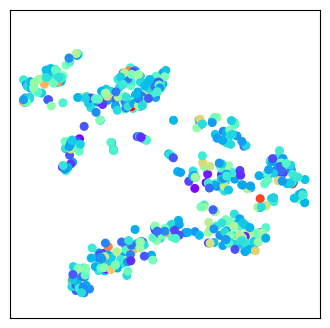

In [76]:
propertylist = [mconnecs, natoms, numN, numS, unique_murcko_ids, pca]

for idx, data in enumerate(tsnes_0):
    # Sets axis limits
    xleft, xright, yleft, yright = setlimits(data)
    # Filters data
    xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [5])
    # Plots
    plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

# TSNE of the SLATM Representation (only ligand atoms that are connected, without feeling the metal)

In [69]:
# Load SLATMs. All_Slatms file has problems to load
slatms = []
for file in os.listdir("/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/Slatms/"):
    if "Ulig" in file:
        slatms.append(load_binary("/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/Slatms/"+file))
print(len(slatms))
slatms = np.array(slatms)

562


In [70]:
slatms.shape

(562, 14404)

In [71]:
# TSNE OF LOCAL SLATMS
perplexities = [50]
tsnes_1 = []

for pval in perplexities: 
    sk_tsne = sk.manifold.TSNE(perplexity=pval, n_jobs=-1)
    tsne = sk_tsne.fit_transform(slatms)
    tsnes_1.append(tsne)

### Plots TSNE and colors by PCA on the Morgan FP of the Ligand Object

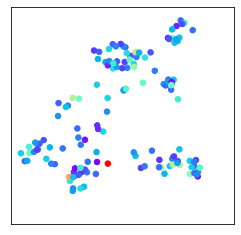

In [122]:
propertylist = [mconnecs, natoms, numN, numS, unique_murcko_ids, pca]

for idx, data in enumerate(tsnes_1):
    # Sets axis limits
    xleft, xright, yleft, yright = setlimits(data)
    # Filters data
    xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [5], filterprop=[0], filterval=2)
    # Plots
    plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

### Colored by Denticity

0 1 62 blue
1 2 143 red
2 3 225 cyan
3 4 80 purple
4 5 18 navy
5 6 34 pink


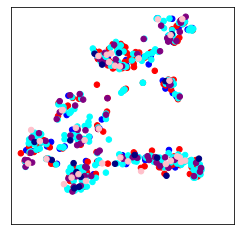

In [123]:
propertylist = [mconnecs, natoms, numN, numS]

for idx, data in enumerate(tsnes_1):
    # Sets axis limits
    xleft, xright, yleft, yright = setlimits(data)
    # Filters data
    xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [0])
    # Plots
    plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

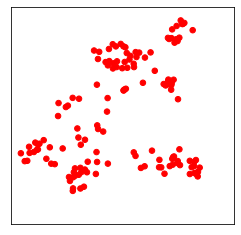

In [124]:
# Filter Bi-dentate ligands
propertylist = [mconnecs, natoms, numN, numS]

for idx, data in enumerate(tsnes_1):
    # Sets axis limits
    xleft, xright, yleft, yright = setlimits(data)
    # Filters data
    xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [0], filterprop=[0], filterval=2)
    # Plots
    plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

## Number of N atoms

0 1 27 blue
1 2 59 red
2 3 100 cyan
3 4 118 purple
4 5 107 navy
5 6 94 pink
6 7 29 gold
7 8 20 black
8 9 7 orange
9 10 1 silver


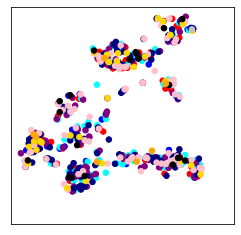

In [125]:
propertylist = [mconnecs, natoms, numN, numS]

for idx, data in enumerate(tsnes_1):
    # Sets axis limits
    xleft, xright, yleft, yright = setlimits(data)
    # Filters data
    xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [2])
    # Plots
    plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

## Number of S atoms

0 0 523 green
1 1 24 blue
2 2 11 red
3 4 4 purple


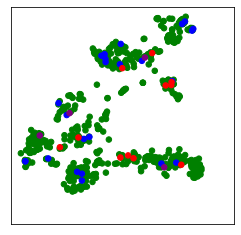

In [126]:
propertylist = [mconnecs, natoms, numN, numS]

for idx, data in enumerate(tsnes_1):
    # Sets axis limits
    xleft, xright, yleft, yright = setlimits(data)
    # Filters data
    xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [3])
    # Plots
    plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

In [ ]:
bla = collections.Counter(propertylist[0])
for b in bla:
    print(b, bla[b])
    hits = [i for i,x in enumerate(propertylist[0]) if x == b]
#     for h in hits:
#         print(b, names[h])

In [ ]:
#### Finds centroid for each subgroup of denticities, and identifies outliers
prop = collections.Counter(propertylist[0])
for idx, t in enumerate(tsnes_1):
    for p in prop:        
        ## Computes centroid
        lst_x = []
        lst_y = []
        sel_index = []
        for jdx, vals in enumerate(t):
            if mconnecs[jdx] == p:
                lst_x.append(vals[0])
                lst_y.append(vals[1])
                sel_index.append(jdx)
        cent_x = np.average(lst_x)
        cent_y = np.average(lst_y)
        cent = np.array([cent_x, cent_y])        
        ## Accumulates the distances to the centroid
        dist = []
        for jdx, vals in enumerate(t):
            if mconnecs[jdx] == p:
                tmp = np.linalg.norm(np.array(vals)-cent)
                dist.append(tmp)        
        outliers, indices = detect_outlier(dist)        
        outlier_names = []
        for kdx in indices:
            outlier_names.append(names[sel_index[kdx]])         
        print("TSNE:", idx, "VAL:", p, len(dist), outlier_names)

## 2nd type of TSNE: PCA

In [ ]:
from sklearn.decomposition import PCA
pcas = []
perplexities = []
for n in range(2,6):
    pca = PCA(n_components=n)
    pca_res = pca.fit_transform(slatms)
    pcas.append(pca_res)
    perplexities.append(n)
#principalDf = pd.DataFrame(data = principalComponents, columns = ['principal component 1', 'principal component 2'])

In [ ]:
# TSNE OF LOCAL SLATMS
perplexities = [10, 50, 100]
tsnes_2 = []

for pval in perplexities: 
    sk_tsne = sk.manifold.TSNE(perplexity=pval, n_jobs=-1)
    tsne = sk_tsne.fit_transform(pcas[3])
    tsnes_2.append(tsne)

In [ ]:
propertylist = [mconnecs, natoms, numN, numS]

for idx, data in enumerate(tsnes_2):
    # Sets axis limits
    xleft, xright, yleft, yright = setlimits(data)
    # Filters data
    xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [0])
    # Plots
    plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

In [ ]:
def plot_slatm(slatm_vector: list):
    fig, axs = plt.subplots(figsize=[16,4])
    xplot = []
    yplot = []
    for idx, v in enumerate(slatm_vector): 
        xplot.append(idx)
        yplot.append(v)
    axs.scatter(xplot,yplot,color='black')
    plt.xlabel("SLATM entry")
    plt.ylabel("Size")
    plt.title("bla")

In [ ]:
plot_slatm(slatms[6])

## 3rd type of TSNE: Global SOAP

In [155]:
soaps = load_binary("/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/SOAPs.npy")
print(len(soaps),"representations loaded")

562 representations loaded


In [156]:
# TSNE OF GLOBAL SOAPS
perplexities = [50]
tsnes_1 = []

for pval in perplexities: 
    sk_tsne = sk.manifold.TSNE(perplexity=pval, n_jobs=-1)
    tsne = sk_tsne.fit_transform(soaps)
    tsnes_1.append(tsne)

0 1 62 blue
1 2 143 red
2 3 225 cyan
3 4 80 purple
4 5 18 navy
5 6 34 pink


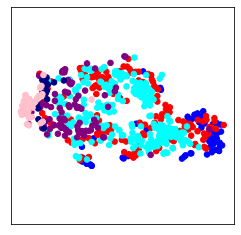

In [157]:
propertylist = [mconnecs, natoms, numN, numS]

for idx, data in enumerate(tsnes_1):
    # Sets axis limits
    xleft, xright, yleft, yright = setlimits(data)
    # Filters data
    xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [0])
    # Plots
    plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

## 4th type of TSNE: Local SOAP

In [158]:
local_soaps = load_binary("/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/SOAPs_Connected.npy")
print(len(local_soaps),"representations loaded")

562 representations loaded


In [159]:
# TSNE OF GLOBAL SOAPS
perplexities = [50]
tsnes_4 = []

for pval in perplexities: 
    sk_tsne = sk.manifold.TSNE(perplexity=pval, n_jobs=-1)
    tsne = sk_tsne.fit_transform(local_soaps)
    tsnes_4.append(tsne)

0 1 62 blue
1 2 143 red
2 3 225 cyan
3 4 80 purple
4 5 18 navy
5 6 34 pink


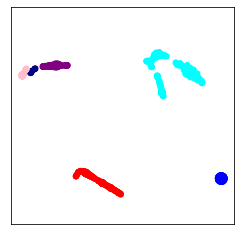

In [160]:
propertylist = [mconnecs, natoms, numN, numS]

for idx, data in enumerate(tsnes_4):
    # Sets axis limits
    xleft, xright, yleft, yright = setlimits(data)
    # Filters data
    xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [0])
    # Plots
    plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

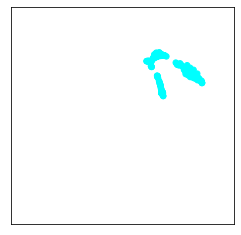

In [161]:
propertylist = [mconnecs, natoms, numN, numS]

for idx, data in enumerate(tsnes_4):
    # Sets axis limits
    xleft, xright, yleft, yright = setlimits(data)
    # Filters data
    xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [0], filterprop=[0], filterval=3)
    # Plots
    plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

## Construct Full SLATM representation of a molecule, from ligand slatms, using ligand_map

In [128]:
ligands_ids = load_binary("/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/list_of_ligands_ids.npy")
# ligands_ids is built as [core, idx, jdx] where idx is the index of the ligand in the complex, and jdx is the unique ligand

In [132]:
## Construct the Complexes Representation as a combination of ligand features, described by another representation
repr_name = 'slatms_wm'

comp_slatms = []
repr      = globals()[repr_name]

for lidx in ligands_ids:
    #print(lidx)
    tmp = []
    for core in lidx:
        #print(core)
        core2, idx, jdx = core
        tmp.append(repr[jdx])
    tmp2 = np.mean(tmp,axis=0)
    comp_slatms.append(tmp2)

save_binary(np.array(comp_slatms),"/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/Slatms_of_Complexes_as_mean_of_unique_ligands_slatm.npy")

## 5th-TSNE Global Complex

In [139]:
complexes = load_binary("/Users/sergivela/Documents/SCOPE/Database_SCO/7-Unique_Ligands/Complexes.npy")

In [140]:
### Extracts other information from Unique Ligands
comp_names  = []
comp_natoms = []

for idx, mol in enumerate(complexes):
    comp_names.append(mol.refcode)
    comp_natoms.append(mol.natoms)

In [142]:
# TSNE OF LOCAL SLATMS
perplexities = [50]
tsnes_5 = []

for pval in perplexities: 
    sk_tsne = sk.manifold.TSNE(perplexity=pval, n_jobs=-1)
    tsne = sk_tsne.fit_transform(np.array(comp_slatms))
    tsnes_5.append(tsne)

In [146]:
# propertylist = [names, natoms]

# for idx, data in enumerate(tsnes_5):
#     # Sets axis limits
#     xleft, xright, yleft, yright = setlimits(data)
#     # Filters data
#     xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [1])
#     # Plots
#     plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

(-29.81282653808594, 35.24630470275879)

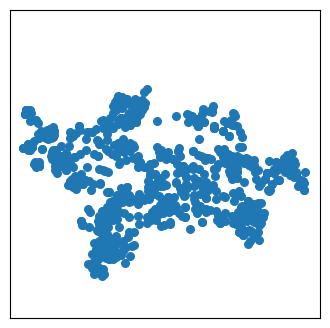

In [156]:
propertylist = [names, natoms]

#filter_tsne_data(data, perplexity, properties, targetproperty, filterprop: list=[], filterval: int=0):
xleft, xright, yleft, yright = setlimits(tsnes_5)

xplot = []
yplot = []
zplot = []
colorlist = ['blue']
cmap = mpl.colors.ListedColormap(colorlist)
for p in tsnes_5[0]:
    xplot.append(p[0])
    yplot.append(p[1])
    zplot.append(int(0))

fig, axs = plt.subplots(figsize=[4,4])
axs.scatter(xplot, yplot, s=30)
axs.yaxis.set_ticklabels([])
axs.yaxis.set_ticks([])
axs.xaxis.set_ticklabels([])
axs.xaxis.set_ticks([])
axs.set_xlim(xleft, xright)
axs.set_ylim(yleft, yright)

## TRASH

In [ ]:
# TSNE OF LOCAL SLATMS
perplexities = [50]
tsnes_3 = []

for pval in perplexities: 
    sk_tsne = sk.manifold.TSNE(perplexity=pval, n_jobs=-1)
    tsne = sk_tsne.fit_transform(sum_soaps)
    tsnes_3.append(tsne)

In [ ]:
propertylist = [mconnecs, natoms, numN, numS]

for idx, data in enumerate(tsnes_3):
    # Sets axis limits
    xleft, xright, yleft, yright = setlimits(data)
    # Filters data
    xplot, yplot, zplot, cmap, plname = filter_tsne_data(data, perplexities[idx], propertylist, [0])
    # Plots
    plot_tsne(xplot, yplot, zplot, cmap, plname, xleft, xright, yleft, yright)

In [ ]:
objects = []
with open("/Users/sergivela/Documents/Docencia/Recursos Informatics/Exercicis/Exercici_Enllaços_Dades.txt", "w") as outfile:
    print("Molecule,Atom1,Atom2,Distance,Bond_Type", file=outfile)
    for kdx, ulig in enumerate(ligs[1:5]):
        mol = ulig.object
        objects.append(mol)
        for idx, a in enumerate(ulig.atoms):
            for jdx, b in enumerate(a.bond):
                if b[1] > b[0]:
                    dist = np.linalg.norm(np.array(ulig.coord[b[0]])-np.array(ulig.coord[b[1]]))
                    if b[2] == 1.0: btext = "SINGLE"
                    elif b[2] == 1.5: btext = "AROMATIC"
                    elif b[2] == 2.0: btext = "DOUBLE"
                    elif b[2] == 3.0: btext = "TRIPLE"
                    print(f"{kdx+1} {ulig.labels[b[0]]} {ulig.labels[b[1]]} {dist:.3f} {btext}", file=outfile)
    #         for jdx, b in enumerate(ulit.atoms):
    #             print(a.label)

In [ ]:
mols2grid.display(objects)

In [ ]:
for m in objects:
    print(Chem.MolToSmiles(m))

In [ ]:
target = ["BLABLA"]

In [ ]:
target = list(bla.lower() for bla in target)
print(target)